# N3 · The point-load lab: spectral bias, domain decomposition and identifiability
**Physics-informed machine learning for civil engineers · demonstration for Block 8 · about 30 minutes to run**

A PINN that is easy for a uniform load struggles when the load is **concentrated**. In this lab we (1) see the failure, (2) name the cause, (3) try the cheap fixes, and (4) remove the problem with **domain decomposition**. At the end we ask a harder question: *what can the sensors actually tell us?*

**The problem (scaled units).** Uniform load `q = 1` plus a point load `P = 1` (30 kN) at mid-span `a = ½`:

`w''''/8 = q + P δ(x − ½)`, with the same supports as before. (`δ` is a spike of unit area: all of `P` is applied at one point.)

| Lab | What it shows | Minutes |
|---|---|---|
| 1 | forward PINN, one network, the point load smeared into a Gaussian of width `s` = 0.2, 0.05, 0.02 (three seeds each) | 8 |
| 2 | cheap fix: extra collocation points near the load | 3 |
| 3 | **domain decomposition**: two networks, the load becomes an *interface condition* | 10 |
| 4 | inverse problem with two unknowns `(q, P)`: what can the data identify? | 10 |
| 5 | read the loss curves: which term is stuck? Weights per term (ReLoBRaLo) and per point (self-adaptive PINN) | 8 |

Labs 1, 2, 3 and 5 are about one failure: a network cannot represent a sharp load (**spectral bias**). Lab 4 is about a different one: deflection readings cannot separate `q` from `P` (**identifiability**). Keeping them apart is the point of this notebook.

> **Demonstration notebook.** There is nothing to fill in: every cell runs as it stands. In the course the instructor shows it already run; to repeat it yourself, choose *Run All* and allow about half an hour.

## Set-up
Same libraries, beam and exact solutions as in N2 (uniform load and point load).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn                    # same libraries as in N0

torch.set_default_dtype(torch.float64)   # 64-bit numbers: needed for clean 4th derivatives (see N0 part 3)
print("PyTorch", torch.__version__, "| numbers are", torch.get_default_dtype())

PyTorch 2.5.1+cu121 | numbers are torch.float64


In [2]:
# ---- The beam, in SI units -------------------------------------------------------------------------
EI   = 1.755e7        # bending stiffness of an IPE 300, N m^2
L    = 3.0            # length of the cantilever, m
Q_SI = 10e3           # uniform load, N/m  (= 10 kN/m)
P_SI = 30e3           # point load, N (= 30 kN = q0 L): P = 1 in scaled units means exactly this

# ---- Scaling: we work with numbers of order 1 (N1 part D shows why this matters) -------------------
# x is measured in units of L, and the deflection in units of W0 = the tip deflection of THIS beam
# under the reference load, so that a correct deflection runs from 0 at the clamp to 1.0 at the tip.
W0 = Q_SI * L**4 / (8 * EI)   # unit of deflection = 5.8 mm  (the textbook tip deflection q L^4 / 8EI)
M0 = EI * W0 / L**2           # what one unit of w''  is worth = 11.25 kN m
F0 = EI * W0 / L**3           # what one unit of w''' is worth = 3.75 kN

def to_mm(w):    return w * W0 * 1e3     # scaled deflection -> millimetres
def to_kNm(M):   return M * M0 / 1e3     # scaled moment     -> kN m
def to_kN(V):    return V * F0 / 1e3     # scaled force      -> kN

# ---- Exact (textbook) solution for the uniform load, in scaled units: q = 1 ----------------------------
# Fixed end at x = 0, free end at x = 1.
def w_unif(x): return x**2 * (6 - 4*x + x**2) / 3      # deflection  w:  0 at the clamp, 1.0 at the tip
def M_unif(x): return 4 * (1 - x)**2                    # bending moment  M = w''   (to_kNm -> kN m)
def V_unif(x): return 8 * (1 - x)                       # shear force     V = -w'''  (to_kN  -> kN)

# The beam equation in these units is  w'''' = 8 q.  The 8 is the same 8 as in the tip deflection q L^4 / 8EI.
# We always divide by it and use the form  w''''/8 = q, which reads: the load the network implies = the load we assume.
GRID = np.linspace(0, 1, 201)                           # 201 points along the beam, used for plots

# ---- Two numbers to judge a fit ------------------------------------------------------------------------
def r2(y, yhat):      return 1 - np.sum((y - yhat)**2) / np.sum((y - y.mean())**2)   # R^2: 1.0 = perfect fit
def rel_l2(y, yhat):  return np.linalg.norm(y - yhat) / np.linalg.norm(y)             # relative error: 0.1 = 10 % off

# ---- Virtual sensor readings: exact deflection + random noise -----------------------------------------------
def make_sensors(n, x_first=0.05, x_last=1.0, noise=0.10, seed=0, q=1.0, P=0.0):
    """n virtual sensors between x_first and x_last. noise = standard deviation as a fraction of the tip deflection."""
    xs = np.linspace(x_first, x_last, n)
    w_exact = q * w_unif(xs)                  # exact deflection at the sensors
    w_tip = q * w_unif(1.0)                   # exact tip deflection (the noise is a fraction of this)
    if P != 0:                                # a point load as well (from N2 part C on)
        w_exact = w_exact + P * w_pt(xs)
        w_tip = w_tip + P * w_pt(1.0)
    ys = w_exact + noise * w_tip * np.random.RandomState(seed).randn(n)    # same seed = same noise every run
    return xs, ys

In [3]:
# ---- Exact solution for a point load P = 1 (30 kN) at x = a = 1/2 (scaled units) ----------------------
def w_pt(x, a=0.5): return 8 * np.where(x <= a, x**2 * (3*a - x) / 6, a**2 * (3*x - a) / 6)   # deflection
def M_pt(x, a=0.5): return 8 * np.where(x <= a, a - x, 0.0)                                     # bending moment
def V_pt(x, a=0.5): return 8 * np.where(x <= a, 1.0, 0.0)                                       # shear (jumps at x = a)

**Plumbing.** Run the next cell once (its code is hidden: click the small `…` to look at it). It only sets up plot style, saving figures for the slides, and a **check function** for the interface loss. You do not need to read it.

In [4]:
import os, json
# colours and plot style (cosmetic)
NAVY, ORANGE, GREY, TEAL, INK = "#002147", "#E9560D", "#9AA5B1", "#1B8C84", "#333F48"
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#5F6B74",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": NAVY, "legend.frameon": False,
    "figure.dpi": 100, "axes.grid": True, "grid.color": "#E3E8EE", "grid.linewidth": 0.8})

# show(fig, name): tidy the layout, display the figure, and (only when run_all.py runs the notebook) save it as a slide figure
FIG_DIR = os.environ.get("PIML_FIG_DIR")
def show(fig, name=None):
    fig.tight_layout()
    if FIG_DIR and name:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# record(key, value) keeps a number for the slides; save_results writes them to results_N?.json (used by run_all.py)
RESULTS = {}
def record(key, value):
    RESULTS[key] = value if isinstance(value, (list, str)) else float(value)
    return value
def save_results(name):
    with open(f"results_{name}.json", "w") as f: json.dump(RESULTS, f, indent=1)

# ---- checks for the TODO cells ---------------------------------------------------------------------------------
STATUS = {}                                    # remembers which TODOs passed
def run_check(label, test, hint="", todo=None):
    """run test() and print PASSED or NOT YET (with a hint). todo = number of the TODO this check belongs to."""
    try:
        ok = bool(test())
    except Exception as e:
        ok = False
        if "NoneType" in str(e): hint = "a TODO line still says `None`: replace it with your expression (see the explanation above the cell)"
        else: hint = f"{hint}  [{type(e).__name__}: {e}]".strip()
    print(("PASSED   " if ok else "NOT YET  ") + label + ("" if ok else "\n          hint: " + hint))
    if todo is not None: STATUS[todo] = ok

def need_todos(*numbers):
    """stop with a clear message if a TODO is not finished (called before the training cells)"""
    missing = [n for n in numbers if not STATUS.get(n)]
    if missing:
        raise RuntimeError(f"TODO {missing} is not finished yet. Go back to it: its check cell must print PASSED.")
def exact_left(x):  return 8 * (x**2 * (6 - 4*x + x**2) / 24 + x**2 * (1.5 - x) / 6)        # exact solution, valid for x <= 1/2
def exact_right(x): return 8 * (x**2 * (6 - 4*x + x**2) / 24 + 0.25 * (3 * x - 0.5) / 6)    # exact solution, valid for x >= 1/2

def check_interface_loss():
    """the exact pair meets correctly for P = 1, and a wrong shear jump (P = 2) is penalised"""
    run_check("interface loss: the exact pair gives zero for P = 1", lambda: interface_loss(exact_left, exact_right, 1.0).item() < 1e-18, todo=1)
    run_check("interface loss: a wrong shear jump (P = 2) is penalised", lambda: interface_loss(exact_left, exact_right, 2.0).item() > 0.9, todo=1)

### Given from N1 and N2
The network, the derivative helper, the boundary loss and the Gaussian ("smeared") point load. `W_EXACT` and `V_EXACT` are the exact deflection and shear force for `q = 1` plus `P = 1`; `err_pct(w)` is the error of a deflection curve against `W_EXACT`.

In [5]:
def make_net(width=30, act=nn.Tanh):
    return nn.Sequential(nn.Linear(1, width), act(), nn.Linear(width, width), act(), nn.Linear(width, 1))

def d(y, x):
    """derivative of y with respect to x at every point (can be differentiated again)"""
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

def derivs(model, x):
    """network output w and its first four derivatives with respect to x"""
    w = model(x)
    w1 = d(w, x)
    w2 = d(w1, x)
    w3 = d(w2, x)
    w4 = d(w3, x)
    return w, w1, w2, w3, w4

def bc_loss(model):
    """the four boundary conditions of the cantilever, squared and summed"""
    xb = torch.tensor([[0.0], [1.0]], requires_grad=True)          # row 0: fixed end, row 1: free end
    w, w1, w2, w3, _ = derivs(model, xb)
    # Each residual is divided by 8 before squaring, for the same reason as w''''/8 in the physics loss:
    # these are derivatives of w, and the 8 is what the scaling put into them. Each term is then a fractional error.
    return (w[0, 0] / 8)**2 + (w1[0, 0] / 8)**2 + (w2[1, 0] / 8)**2 + (w3[1, 0] / 8)**2

In [6]:
def evaluate(model, xg=GRID):
    """w, w', w'', w''', w'''' of the network on a grid, as numpy arrays"""
    x = torch.tensor(xg.reshape(-1, 1), requires_grad=True)
    return [t.detach().numpy().ravel() for t in derivs(model, x)]

def gauss(x, s, a=0.5):
    """unit-area Gaussian of width s centred at x = a: the point load smeared over a small width"""
    return torch.exp(-(x - a)**2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi))

W_EXACT = w_unif(GRID) + w_pt(GRID)                  # exact deflection for q = 1 and P = 1
V_EXACT = V_unif(GRID) + V_pt(GRID)                  # exact shear force: it JUMPS by P at x = 1/2

def err_pct(w):
    """error (%) of a deflection curve w on the grid, against the exact deflection W_EXACT"""
    return 100 * rel_l2(W_EXACT, w)

**Check (optional, no training).** Smearing the spike into a Gaussian changes the problem slightly. How much does it change the *exact* answer? We integrate the beam equation numerically for each width.

In [7]:
def cumulative_integral(f, h):
    """running integral of f from the first grid point to every grid point (trapezoid rule, grid spacing h)"""
    return np.concatenate([[0.0], np.cumsum(0.5 * (f[1:] + f[:-1]) * h)])

def w_smeared_exact(s, a=0.5, n=4001):
    """exact deflection when the point load is smeared into a Gaussian of width s (numerical integration)"""
    x = np.linspace(0, 1, n)
    h = x[1] - x[0]
    load = 1 + np.exp(-(x - a)**2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi))     # the load: w''''/8 = q + Gaussian
    shear = cumulative_integral(load, h)
    shear = shear[-1] - shear                          # shear force V(x) = load to the right of x
    moment = cumulative_integral(shear, h)
    moment = moment[-1] - moment                       # moment M(x) = integral of V from x to 1
    w = 8 * cumulative_integral(cumulative_integral(moment, h), h)             # w = integral of integral of M, x8 for our units
    return np.interp(GRID, x, w)

for s in (0.2, 0.05, 0.02):
    print(f"smearing with s = {s}: the exact deflection changes by {100 * rel_l2(W_EXACT, w_smeared_exact(s)):.3f} %")

smearing with s = 0.2: the exact deflection changes by 2.601 %
smearing with s = 0.05: the exact deflection changes by 0.216 %
smearing with s = 0.02: the exact deflection changes by 0.035 %


## Lab 1 · One network, a Gaussian load: the error tends to grow as the load gets narrower
In N2 part C (class experiment 2) each of you trained **one** width, as an inverse problem with two unknown loads. Here both loads are **given** and we train **three widths with three seeds**, so that the scatter can be seen as well as the trend. Physics residual: `w''''/8 − 1 − Gauss(x; ½, s)`. Same network, optimiser and 5,000 iterations as in N1, with 100 fresh collocation points per iteration: **9 trainings, about 6 minutes in total.** Every training prints its losses every 1,000 iterations.

Nothing is unknown here: both loads are given. Any error is the network failing to represent a load it was handed — that is spectral bias, and nothing to do with the measurements.

In [8]:
def train_single(s, its=5000, lr=5e-3, n_col=100, n_near=0, seed=0, print_every=1000, verbose=True):
    """Forward PINN with ONE network for  w''''/8 = 1 + Gauss(x; 1/2, s).  n_near = extra collocation points near the load (Lab 2)."""
    torch.manual_seed(seed)
    model = make_net()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for it in range(its):
        x = torch.rand(n_col, 1)                                                  # random collocation points in (0, 1)
        if n_near > 0:
            x_near = 0.4 + 0.2 * torch.rand(n_near, 1)                            # extra points in [0.4, 0.6], near the load
            x = torch.cat([x, x_near])
        x.requires_grad_(True)
        w4 = derivs(model, x)[4]
        L_phys = ((w4 / 8 - 1.0 - gauss(x, s)) ** 2).mean()                           # physics, with the Gaussian load
        L_bc = bc_loss(model)                                                     # supports
        loss = L_phys + L_bc
        opt.zero_grad()
        loss.backward()
        opt.step()
        if verbose and (it % print_every == 0 or it == its - 1):
            print(f"     iteration {it:5d} | loss {loss.item():10.3e} | physics {L_phys.item():10.3e} | boundary {L_bc.item():10.3e}", flush=True)
    return model

In [9]:
widths = [0.2, 0.05, 0.02]                             # load widths to try
seeds = [0, 1, 2]                                      # random starts to try
err_lab1 = np.zeros((3, 3))                            # error (%): one row per width, one column per seed
models1 = {}                                           # the seed-0 network of each width (kept for the plots)
for i, s in enumerate(widths):
    for j, seed in enumerate(seeds):
        print(f"--- width s = {s}, seed {seed}", flush=True)
        model = train_single(s, its=5000, seed=seed)
        err_lab1[i, j] = err_pct(evaluate(model)[0])
        if seed == 0:
            models1[s] = model

print("\nwidth s    error seed 0   seed 1   seed 2")
for i, s in enumerate(widths):
    print(f"{s:7.2f}    " + "   ".join(f"{e:6.1f} %" for e in err_lab1[i]))

--- width s = 0.2, seed 0
     iteration     0 | loss  4.883e+00 | physics  4.883e+00 | boundary  3.868e-04
     iteration  1000 | loss  4.947e-04 | physics  4.441e-04 | boundary  5.059e-05
     iteration  2000 | loss  9.263e-04 | physics  9.074e-04 | boundary  1.883e-05
     iteration  3000 | loss  7.893e-04 | physics  7.830e-04 | boundary  6.297e-06
     iteration  4000 | loss  5.890e-04 | physics  5.853e-04 | boundary  3.621e-06
     iteration  4999 | loss  1.307e-04 | physics  1.277e-04 | boundary  2.959e-06
--- width s = 0.2, seed 1
     iteration     0 | loss  3.931e+00 | physics  3.929e+00 | boundary  2.540e-03
     iteration  1000 | loss  9.727e-05 | physics  6.469e-05 | boundary  3.258e-05
     iteration  2000 | loss  1.758e-04 | physics  1.704e-04 | boundary  5.459e-06
     iteration  3000 | loss  5.653e-05 | physics  5.458e-05 | boundary  1.960e-06
     iteration  4000 | loss  2.658e-05 | physics  2.590e-05 | boundary  6.785e-07
     iteration  4999 | loss  1.631e-02 | physi

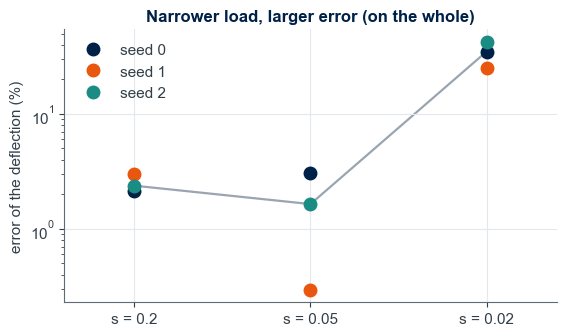

In [10]:
fig, ax = plt.subplots(figsize=(5.8, 3.5))
colours = [NAVY, ORANGE, TEAL]
for j, seed in enumerate(seeds):
    ax.semilogy(range(3), err_lab1[:, j], "o", color=colours[j], ms=9, label=f"seed {seed}")
ax.semilogy(range(3), np.median(err_lab1, axis=1), "-", color=GREY, lw=1.6, zorder=0)       # median of the three seeds
ax.set_xticks(range(3))
ax.set_xticklabels([f"s = {s}" for s in widths])
ax.set(xlim=(-0.4, 2.4), ylabel="error of the deflection (%)", title="Narrower load, larger error (on the whole)")
ax.legend(loc="upper left")
show(fig, "n3_err_vs_s")

**Why? Look at the fourth derivative.** The beam equation says `w''''/8 = load`. For this lab the load is `1 + Gaussian`: the uniform load plus the point load smeared over a width `s`. So a network that solves the problem must have a fourth derivative with a **narrow peak** at x = ½, and a shear force `w'''` that drops steeply there.

Networks learn smooth, slowly varying shapes first and sharp features very slowly: this is called **spectral bias**. The figure below has three panels:

| Panel | What is plotted | What to look for |
|---|---|---|
| left | the **required** load `1 + Gaussian` for the three widths | the narrower the load, the taller the peak the network has to build (the area under the peak is always `P = 1`) |
| middle | for `s = 0.02`: the required load (navy) and the **fourth derivative of the trained network** (orange) | if the PINN had solved the problem, the two curves would coincide. Compare the two peak heights printed above the figure |
| right | the shear force: exact (navy) and from the trained network, `−w'''` (orange) | the exact shear drops by `P` = 30 kN at the load; the network spreads the drop out and overshoots |

s = 0.02:  peak of the required load = 20.9      peak of the load the network builds = 11.6


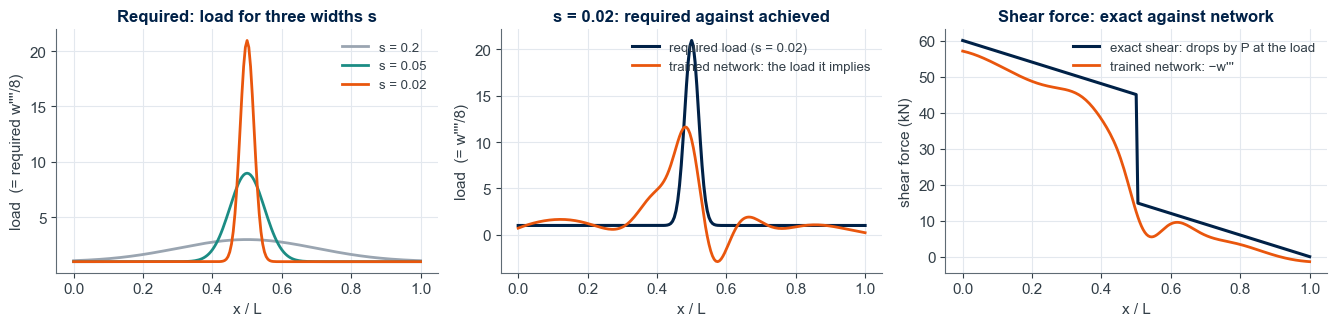

In [11]:
x_grid = torch.tensor(GRID.reshape(-1, 1))                              # grid as a tensor (no gradients needed here)

def target_load(s):
    """the load that w''''/8 must equal: the uniform load 1 plus the Gaussian of width s"""
    return 1 + gauss(x_grid, s).numpy().ravel()

w_net, w1_net, w2_net, w3_net, w4_net = evaluate(models1[0.02])         # single network, s = 0.02, seed 0
print(f"s = 0.02:  peak of the required load = {target_load(0.02).max():.1f}      peak of the load the network builds = {w4_net.max() / 8:.1f}")

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.4))
for s, colour in zip(widths, (GREY, TEAL, ORANGE)):
    ax[0].plot(GRID, target_load(s), color=colour, lw=2, label=f"s = {s}")
ax[0].set(xlabel="x / L", ylabel="load  (= required w''''/8)", title="Required: load for three widths s")
ax[0].legend(fontsize=9.5)
ax[1].plot(GRID, target_load(0.02), color=NAVY, lw=2.2, label="required load (s = 0.02)")
ax[1].plot(GRID, w4_net / 8, color=ORANGE, lw=2, label="trained network: the load it implies")
ax[1].set(xlabel="x / L", ylabel="load  (= w''''/8)", title="s = 0.02: required against achieved")
ax[1].legend(fontsize=9.5)
ax[2].plot(GRID, to_kN(V_EXACT), color=NAVY, lw=2.2, label="exact shear: drops by P at the load")
ax[2].plot(GRID, to_kN(-w3_net), color=ORANGE, lw=2, label="trained network: −w'''")
ax[2].set(xlabel="x / L", ylabel="shear force (kN)", title="Shear force: exact against network")
ax[2].legend(fontsize=9.5)
show(fig, "n3_spike")

## Lab 2 · Cheap fix: more collocation points where the load is
40 extra random points in [0.4, 0.6] at every iteration, `s = 0.02`, same three seeds (3 trainings).

In [12]:
near = []                                                      # errors with 40 extra points near the load, one per seed
for seed in seeds:
    print(f"--- s = 0.02, seed {seed}, + 40 near-load points", flush=True)
    model = train_single(0.02, n_near=40, seed=seed)
    near.append(err_pct(evaluate(model)[0]))
base = err_lab1[2]                                             # without the extra points: the row s = 0.02 from Lab 1

print("\nseed    baseline    + 40 near-load points")
for k, seed in enumerate(seeds):
    print(f"{seed:4d}   {base[k]:8.1f} %   {near[k]:12.1f} %")

--- s = 0.02, seed 0, + 40 near-load points
     iteration     0 | loss  3.867e+01 | physics  3.867e+01 | boundary  3.868e-04
     iteration  1000 | loss  4.605e+00 | physics  4.587e+00 | boundary  1.853e-02
     iteration  2000 | loss  1.009e+01 | physics  1.007e+01 | boundary  1.747e-02
     iteration  3000 | loss  2.161e+00 | physics  2.155e+00 | boundary  5.274e-03
     iteration  4000 | loss  3.448e+00 | physics  3.445e+00 | boundary  3.602e-03
     iteration  4999 | loss  1.813e+00 | physics  1.807e+00 | boundary  5.362e-03
--- s = 0.02, seed 1, + 40 near-load points
     iteration     0 | loss  3.118e+01 | physics  3.118e+01 | boundary  2.540e-03
     iteration  1000 | loss  6.870e+00 | physics  6.830e+00 | boundary  3.957e-02
     iteration  2000 | loss  3.115e+00 | physics  3.094e+00 | boundary  2.101e-02
     iteration  3000 | loss  2.210e+00 | physics  2.194e+00 | boundary  1.567e-02
     iteration  4000 | loss  1.137e+00 | physics  1.131e+00 | boundary  6.884e-03
     itera

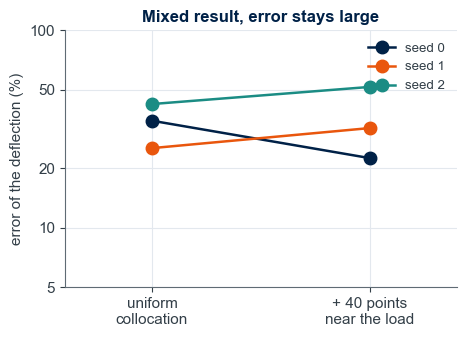

In [13]:
fig, ax = plt.subplots(figsize=(4.8, 3.5))
for k in range(3):
    ax.semilogy([0, 1], [base[k], near[k]], "o-", color=[NAVY, ORANGE, TEAL][k], lw=1.8, ms=9, label=f"seed {seeds[k]}")
ax.set_xticks([0, 1])
ax.set_xticklabels(["uniform\ncollocation", "+ 40 points\nnear the load"])
ax.set(xlim=(-0.4, 1.4), ylabel="error of the deflection (%)", title="Mixed result, error stays large")
ax.set_yticks([5, 10, 20, 50, 100])
ax.set_yticklabels(["5", "10", "20", "50", "100"])
ax.minorticks_off()
ax.legend(loc="upper right", fontsize=9.5, frameon=False)
show(fig, "n3_cheap")

**Take-away.** Look at the two columns: extra collocation points near the load do **not** fix the problem reliably. The error changes from seed to seed (it can go down for one seed and up for another) and stays far above what the next lab reaches, because the network still has to *build* a spike. Other remedies exist (adaptive weights, residual-based refinement, Fourier features); we have not tested them here. The next lab **removes the spike** instead.

## Lab 3 · Domain decomposition: the point load as an interface condition
Cut the beam at the load. Use **two small, smooth networks**: left (0 to ½) and right (½ to 1). Each one only has to satisfy `w''''/8 = q`: no spike anywhere. The load `P` enters only through **how the two networks connect** at `x = ½`:

```
 fixed |——— left network ———●——— right network ———| free
 x = 0                    x = ½  (point load P)             x = 1
```

| at x = ½ | condition | why |
|---|---|---|
| deflection | `w_left = w_right` | the beam does not break |
| slope | `w'_left = w'_right` | no kink |
| moment | `w''_left = w''_right` | no concentrated moment is applied |
| shear | `w'''_right − w'''_left = P` | the shear force **jumps by exactly the point load** |

### The interface loss
The four conditions of the table, each written as a squared term; `interface_loss` returns their sum. This single function carries the point load into the PINN: the load is an *exact condition* between two smooth networks, not a spike to be resolved. `l0, l1, l2, l3` are the left network's `w, w', w'', w'''` at `x = ½`; `r0, r1, r2, r3` are the right network's. Each difference is divided by 8, the same factor as in the beam equation, so that all four are fractions of the load.


In [14]:
def interface_loss(netL, netR, P):
    """the four conditions at x = 1/2 where the two networks meet (each squared, then summed)"""
    xa = torch.tensor([[0.5]], requires_grad=True)       # the interface point
    l0, l1, l2, l3, _ = derivs(netL, xa)                 # left network:  w, w', w'', w''' at x = 1/2
    r0, r1, r2, r3, _ = derivs(netR, xa)                 # right network: w, w', w'', w''' at x = 1/2
    jump_w      = ((l0 - r0) / 8) ** 2       # the deflection is continuous
    jump_slope  = ((l1 - r1) / 8) ** 2       # the slope is continuous
    jump_moment = ((l2 - r2) / 8) ** 2       # the moment is continuous
    jump_shear  = ((r3 - l3) / 8 - P) ** 2   # the shear JUMPS by the point load P
    return (jump_w + jump_slope + jump_moment + jump_shear).sum()      # sum of the four terms, as one number

**Check.** We feed the exact solution to the left and to the right of the load (two *different* formulas, one for each side). They meet correctly, so the interface loss must be ≈ 0 for `P = 1`, and clearly positive for a wrong shear jump (`P = 2`).

In [15]:
check_interface_loss()

PASSED   interface loss: the exact pair gives zero for P = 1
PASSED   interface loss: a wrong shear jump (P = 2) is penalised


### The two-network PINN
We split the loss into small pieces, one per physical statement:

| function | what it checks |
|---|---|
| `dd_physics_loss` | `w''''/8 = q` on both sides (random collocation points left and right of ½) |
| `dd_bc_loss` | fixed end (left network at x = 0), free end (right network at x = 1) |
| `interface_loss` | the networks connect, and the shear jumps by `P` |

The constraints (boundary + interface) get a **weight of 10** so that they are not outvoted by the physics term. Both networks are trained by **one optimiser**.

In [16]:
A_ = 0.5          # position of the point load = the interface between the two networks

def dd_physics_loss(netL, netR, q, n_col=50):
    """beam equation w''''/8 = q on both sides: 50 random collocation points left of 1/2 and 50 right of 1/2"""
    xl = (A_ * torch.rand(n_col, 1)).requires_grad_(True)                    # left points, in (0, 1/2)
    xr = (A_ + (1 - A_) * torch.rand(n_col, 1)).requires_grad_(True)         # right points, in (1/2, 1)
    l4 = derivs(netL, xl)[4]
    r4 = derivs(netR, xr)[4]
    return ((l4 / 8 - q) ** 2).mean() + ((r4 / 8 - q) ** 2).mean()

def dd_bc_loss(netL, netR):
    """supports: the fixed end belongs to the LEFT network (x = 0), the free end to the RIGHT network (x = 1)"""
    x0 = torch.tensor([[0.0]], requires_grad=True)
    x1 = torch.tensor([[1.0]], requires_grad=True)
    wl0, wl1 = derivs(netL, x0)[:2]              # left network at the fixed end: w, w'
    wr2, wr3 = derivs(netR, x1)[2:4]             # right network at the free end: w'', w'''
    return wl0[0, 0]**2 + wl1[0, 0]**2 + wr2[0, 0]**2 + wr3[0, 0]**2

In [17]:
def train_dd_forward(its=5000, lr=5e-3, seed=0, q=1.0, P=1.0, w_c=10.0, print_every=1000, verbose=True):
    """Forward problem with two networks (q and P known). loss = physics + w_c * (boundary + interface)."""
    torch.manual_seed(seed)
    netL = make_net()
    netR = make_net()
    opt = torch.optim.Adam(list(netL.parameters()) + list(netR.parameters()), lr=lr)      # ONE optimiser for BOTH networks
    for it in range(its):
        L_phys = dd_physics_loss(netL, netR, q)
        L_con = dd_bc_loss(netL, netR) + interface_loss(netL, netR, P)      # constraints: supports + interface
        loss = L_phys + w_c * L_con
        opt.zero_grad()
        loss.backward()
        opt.step()
        if verbose and (it % print_every == 0 or it == its - 1):
            print(f"     iteration {it:5d} | loss {loss.item():10.3e} | physics {L_phys.item():10.3e} | boundary + interface {L_con.item():10.3e}", flush=True)
    return netL, netR

def eval_dd(netL, netR, xg=GRID):
    """w, w', w'', w''' of the two-network model on a grid: left network up to x = 1/2, right network after it"""
    left = evaluate(netL, xg[xg <= A_])               # five arrays: w, w', w'', w''', w''''
    right = evaluate(netR, xg[xg > A_])
    w = np.concatenate([left[0], right[0]])
    w1 = np.concatenate([left[1], right[1]])
    w2 = np.concatenate([left[2], right[2]])
    w3 = np.concatenate([left[3], right[3]])
    return w, w1, w2, w3

Train three seeds (about 3 minutes) and compare with the single network of Lab 1:

In [18]:
dd = []                                                       # error (%) of the two-network model, one per seed
dd_models = []                                                # the trained pairs of networks
for seed in seeds:
    print(f"--- two networks, seed {seed}", flush=True)
    nL, nR = train_dd_forward(its=5000, seed=seed)
    dd_models.append((nL, nR))
    dd.append(err_pct(eval_dd(nL, nR)[0]))

print("\nseed    domain decomposition, error of the deflection")
for k, seed in enumerate(seeds):
    print(f"{seed:4d}    {dd[k]:6.2f} %")
print(f"single network at s = 0.02: {', '.join(f'{e:.1f} %' for e in base)}")

--- two networks, seed 0
     iteration     0 | loss  1.189e+01 | physics  2.152e+00 | boundary + interface  9.742e-01
     iteration  1000 | loss  5.558e-03 | physics  3.208e-03 | boundary + interface  2.349e-04
     iteration  2000 | loss  3.071e-03 | physics  1.795e-03 | boundary + interface  1.277e-04
     iteration  3000 | loss  3.979e-03 | physics  8.867e-04 | boundary + interface  3.092e-04
     iteration  4000 | loss  6.396e-04 | physics  3.805e-04 | boundary + interface  2.591e-05
     iteration  4999 | loss  3.302e-03 | physics  1.394e-03 | boundary + interface  1.908e-04
--- two networks, seed 1
     iteration     0 | loss  1.355e+01 | physics  1.845e+00 | boundary + interface  1.170e+00
     iteration  1000 | loss  1.494e-01 | physics  2.999e-02 | boundary + interface  1.194e-02
     iteration  2000 | loss  2.697e-03 | physics  5.726e-04 | boundary + interface  2.124e-04
     iteration  3000 | loss  4.211e-02 | physics  8.305e-04 | boundary + interface  4.128e-03
     itera

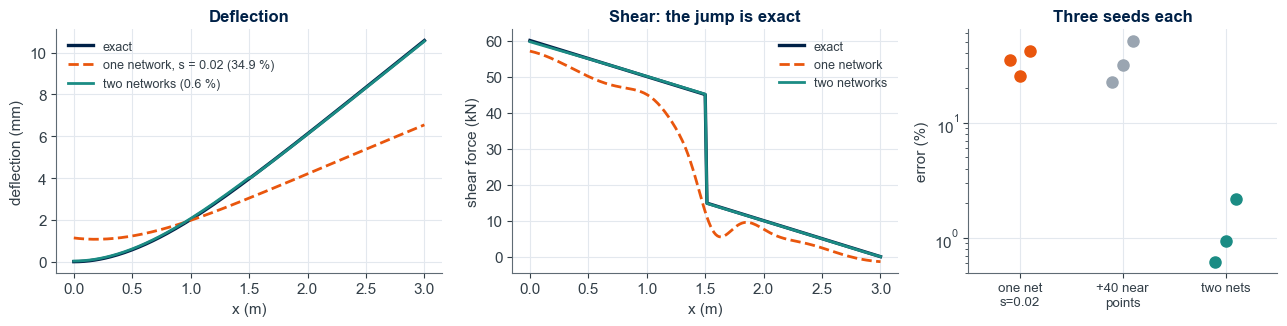

In [19]:
nL, nR = dd_models[0]
w_dd, _, _, w3_dd = eval_dd(nL, nR)                          # seed-0 two-network model
w_one = evaluate(models1[0.02])[0]                           # seed-0 single network, s = 0.02: deflection
w3_one = evaluate(models1[0.02])[3]                          # ... and w'''
xm = GRID * L                                                # position in metres
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
ax[0].plot(xm, to_mm(W_EXACT), color=NAVY, lw=2.4, label="exact")
ax[0].plot(xm, to_mm(w_one), color=ORANGE, lw=2, ls="--", label=f"one network, s = 0.02 ({err_lab1[2, 0]:.1f} %)")
ax[0].plot(xm, to_mm(w_dd), color=TEAL, lw=2, label=f"two networks ({dd[0]:.1f} %)")
ax[0].set(xlabel="x (m)", ylabel="deflection (mm)", title="Deflection")
ax[0].legend(loc="upper left", fontsize=9)
ax[1].plot(xm, to_kN(V_EXACT), color=NAVY, lw=2.4, label="exact")
ax[1].plot(xm, to_kN(-w3_one), color=ORANGE, lw=2, ls="--", label="one network")
ax[1].plot(xm, to_kN(-w3_dd), color=TEAL, lw=2, label="two networks")
ax[1].set(xlabel="x (m)", ylabel="shear force (kN)", title="Shear: the jump is exact")
ax[1].legend(loc="upper right", fontsize=9)
shift = np.array([-0.1, 0.0, 0.1])                           # small horizontal shifts, so the three seeds do not overlap
ax[2].semilogy(0 + shift, base, "o", color=ORANGE, ms=8)
ax[2].semilogy(1 + shift, near, "o", color=GREY, ms=8)
ax[2].semilogy(2 + shift, dd, "o", color=TEAL, ms=8)
ax[2].set_xticks(range(3))
ax[2].set_xticklabels(["one net\ns=0.02", "+40 near\npoints", "two nets"], fontsize=9.5)
ax[2].set(xlim=(-0.5, 2.5), ylabel="error (%)", title="Three seeds each")
show(fig, "n3_dd")

**Take-away.** The point load is now an **exact condition** between two smooth networks, not a feature to be resolved. Compare with the single network: the error is much smaller, and the three seeds are much closer to each other (the exact numbers differ from machine to machine).

## Lab 4 · The inverse problem with two unknowns: what can the data identify?
Sixteen deflection readings with 10 % noise; true `q = 1` and `P = 1`; **both unknown**.

### 4a · Before training: what is identifiable? (numpy only, no network)
For a linear model `w(x) = q · w_unif(x) + P · w_pt(x)`, the uncertainty of `(q, P)` follows from the **sensor positions alone**. First, how different are the two deflection shapes *at our sensors*? We compare the two columns "deflection per unit `q`" and "deflection per unit `P`":

In [20]:
xs_i = np.linspace(0.05, 1.0, 16)                                  # the 16 sensor positions
Adef = np.stack([w_unif(xs_i), w_pt(xs_i)], axis=1)                # 16 rows x 2 columns: column 1 = per unit q, column 2 = per unit P
sig_w = 0.10 * (w_unif(1.0) + w_pt(1.0))                           # noise (standard deviation): 10 % of the tip deflection

cosine = Adef[:, 0] @ Adef[:, 1] / np.linalg.norm(Adef[:, 0]) / np.linalg.norm(Adef[:, 1])
print(f"similarity of the two deflection shapes at the sensors: {cosine:.3f}   (1.000 = identical shape)")

similarity of the two deflection shapes at the sensors: 0.999   (1.000 = identical shape)


The two shapes are nearly the same, so noise in the readings can be traded between `q` and `P`. How much exactly? Least squares gives the **covariance** of the estimates, `(AᵀA / σ²)⁻¹`, from which we read the **standard deviation** of each estimate and the **correlation** between them. We try four sets of sensors: deflections only, and with *moment gauges* added (a moment gauge **outside** the load sees only `q`; one **at the fixed end** sees `(q + P)/2`).

In [21]:
outer = np.array([0.55, 0.65, 0.75, 0.85])                                  # four moment gauges to the right of the load
rows_outer = np.zeros((4, 2))                                               # a moment gauge there sees q only: M = q (1-x)^2 / 2
rows_outer[:, 0] = (1 - outer) ** 2 / 2
row_root = np.array([[0.5, 0.5]])                                           # moment at the fixed end: (q + P) / 2

def uncertainty(extra_rows=None, extra_sig=0.01):
    """standard deviation of (q, P) and their correlation, for the deflection sensors + optional moment gauges"""
    W = Adef / sig_w                                                        # each reading divided by its noise
    if extra_rows is not None:
        W = np.vstack([W, extra_rows / extra_sig])                          # gauges: noise 1 % of the root moment
    cov = np.linalg.inv(W.T @ W)                                            # covariance of the least-squares estimate
    sd = np.sqrt(np.diag(cov))
    return sd, cov[0, 1] / sd[0] / sd[1]

case_names = ["deflections only", "+ 4 moment gauges outside the load", "+ moment gauge at the fixed end", "+ both"]
case_rows = [None, rows_outer, row_root, np.vstack([rows_outer, row_root])]
ident_res = {}                                                              # case name -> (standard deviations, correlation)
print(f"{'sensors':38s}  sd(q)   sd(P)   correlation")
for name, rows in zip(case_names, case_rows):
    sd, corr = uncertainty(rows)
    ident_res[name] = (sd, corr)
    print(f"{name:38s}  {sd[0]:.2f}    {sd[1]:.2f}    {corr:+.2f}")

sensors                                 sd(q)   sd(P)   correlation
deflections only                        2.17    2.51    -1.00
+ 4 moment gauges outside the load      0.08    0.14    -0.69
+ moment gauge at the fixed end         0.62    0.63    -1.00
+ both                                  0.08    0.08    -0.97


Read the table: with deflections only the standard deviations are of order one (the same size as the true values!) and the correlation is close to −1: only the *sum* `q + P` is determined. Gauges that see `q` and `P` **differently** make the split identifiable. Now a simulation to *see* it: 300 noisy data sets, one least-squares estimate each.

In [22]:
rng = np.random.RandomState(0)
gauge_rows = np.vstack([rows_outer, row_root])                  # the five moment gauges
est_a, est_b = [], []                                           # estimates (q, P): deflections only / with gauges
for _ in range(300):
    y = Adef @ np.array([1.0, 1.0]) + sig_w * rng.randn(16)                 # noisy deflection readings (true q = P = 1)
    g = gauge_rows @ np.array([1.0, 1.0]) + 0.01 * rng.randn(5)             # noisy moment readings
    est_a.append(np.linalg.lstsq(Adef, y, rcond=None)[0])
    both = np.vstack([Adef / sig_w, gauge_rows / 0.01])                     # all readings, each divided by its noise
    est_b.append(np.linalg.lstsq(both, np.concatenate([y / sig_w, g / 0.01]), rcond=None)[0])
est_a, est_b = np.array(est_a), np.array(est_b)

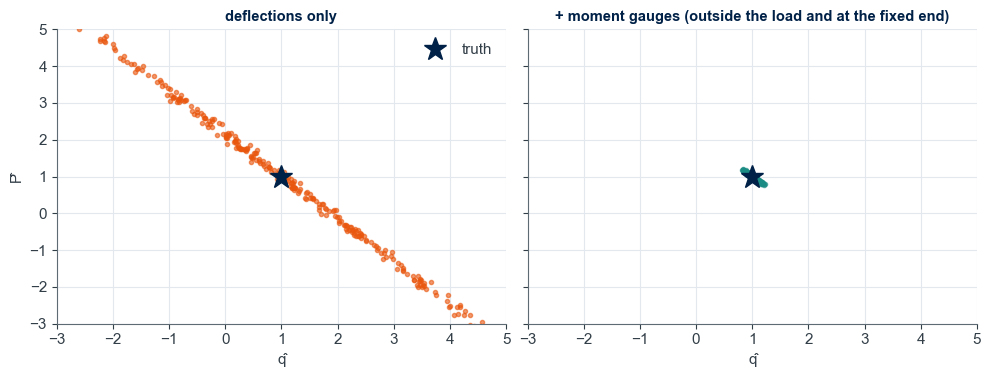

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.9), sharex=True, sharey=True)
ax[0].plot(est_a[:, 0], est_a[:, 1], ".", color=ORANGE, ms=6, alpha=0.6)
ax[0].set_title("deflections only", fontsize=10.5)
ax[1].plot(est_b[:, 0], est_b[:, 1], ".", color=TEAL, ms=6, alpha=0.6)
ax[1].set_title("+ moment gauges (outside the load and at the fixed end)", fontsize=10.5)
for panel in ax:
    panel.plot([1], [1], "*", color=NAVY, ms=17, label="truth")
    panel.set_xlabel("q̂")
ax[0].set_ylabel("P̂")
ax[0].legend(loc="upper right")
ax[0].set_xlim(-3, 5)
ax[0].set_ylim(-3, 5)
show(fig, "n3_ident")

### 4b · The two-network inverse PINN
Now the PINN: the two-network model with **both loads unknown** (starting at 0.37), trained from deflections only, and with moment gauges added (four outside the load and one at the fixed end, noise 1 % of the root moment). Three noise draws each, **6 trainings, about 6 minutes**. The losses and the two recovered loads are printed every 1,000 iterations.

The inverse loss has the same pieces as in N2: `0.4 · data + 0.4 · physics + 0.2 · boundary`, plus `10 ·` interface. The data term now also includes the moment gauges (the network's `w''` at the gauge positions must match the measured moments).

In [24]:
def dd_data_loss(netL, netR, xs, ys):
    """deflection readings: sensors left of the load go to the left network, the others to the right network"""
    left = xs <= A_                                                         # True for sensors in the left half
    XL = torch.tensor(xs[left].reshape(-1, 1))
    YL = torch.tensor(ys[left].reshape(-1, 1))
    XR = torch.tensor(xs[~left].reshape(-1, 1))
    YR = torch.tensor(ys[~left].reshape(-1, 1))
    misfit = ((netL(XL) - YL) ** 2).sum() + ((netR(XR) - YR) ** 2).sum()
    return misfit / ys.max() ** 2 / len(xs)                                 # divided by the largest reading squared, and by the number of readings

def dd_gauge_loss(netL, netR, gx, gy):
    """moment gauges: the network's w'' at the gauge positions gx must match the measured moments gy"""
    left = gx <= A_                                                         # True for gauges in the left half
    xl = torch.tensor(gx[left].reshape(-1, 1), requires_grad=True)          # requires_grad: we need w'' there
    xr = torch.tensor(gx[~left].reshape(-1, 1), requires_grad=True)
    yl = torch.tensor(gy[left].reshape(-1, 1))
    yr = torch.tensor(gy[~left].reshape(-1, 1))
    misfit_left = ((derivs(netL, xl)[2] - yl) ** 2).sum()                   # w'' of the left network at the left gauges
    misfit_right = ((derivs(netR, xr)[2] - yr) ** 2).sum()                  # w'' of the right network at the right gauges
    return (misfit_left + misfit_right) / len(gx)

In [25]:
def train_dd_inverse(xs, ys, gauges=None, its=4000, lr=5e-3, lr_load=2e-2, seed=0, w_c=10.0, wts=(0.4, 0.4, 0.2),
                     print_every=1000, verbose=True):
    """Inverse problem with two networks: q and P are unknown. gauges = (positions, measured moments), optional.
    Returns both networks and a history: rows [iteration, q, P]."""
    torch.manual_seed(seed)
    netL = make_net()
    netR = make_net()
    log_q = torch.tensor(-1.0, requires_grad=True)               # trainable log q and log P, start at q = P = 0.37
    log_P = torch.tensor(-1.0, requires_grad=True)
    opt = torch.optim.Adam(list(netL.parameters()) + list(netR.parameters()), lr=lr)     # optimiser 1: the two networks
    opt_load = torch.optim.Adam([log_q, log_P], lr=lr_load)                              # optimiser 2: the two unknown loads
    history = []
    for it in range(its):
        q = torch.exp(log_q)                                     # positive loads
        P = torch.exp(log_P)
        L_data = dd_data_loss(netL, netR, xs, ys)
        if gauges is not None:
            L_data = L_data + dd_gauge_loss(netL, netR, gauges[0], gauges[1])
        L_phys = dd_physics_loss(netL, netR, q)
        L_bc = dd_bc_loss(netL, netR)
        L_int = interface_loss(netL, netR, P)
        loss = wts[0] * L_data + wts[1] * L_phys + wts[2] * L_bc + w_c * L_int
        opt.zero_grad()
        opt_load.zero_grad()
        loss.backward()
        opt.step()
        opt_load.step()
        if it % print_every == 0 or it == its - 1:
            history.append([it, torch.exp(log_q).item(), torch.exp(log_P).item()])
            if verbose:
                print(f"     iteration {it:5d} | loss {loss.item():10.3e} | q = {history[-1][1]:.3f}   P = {history[-1][2]:.3f}", flush=True)
    return netL, netR, np.array(history)

In [26]:
gx = np.array([0.0, 0.55, 0.65, 0.75, 0.85])                      # moment gauges: fixed end + four outside the load
inv_defl = []                                                     # one row per noise draw: [q_hat, P_hat, R2 of the deflection]
inv_gauge = []
for draw in range(3):
    xs_p, ys_p = make_sensors(16, 0.05, 1.0, 0.10, seed=draw, q=1.0, P=1.0)
    gy = M_unif(gx) + M_pt(gx) + 0.01 * np.random.RandomState(100 + draw).randn(len(gx))      # exact moments + noise

    print(f"--- noise draw {draw}: deflections only", flush=True)
    nL, nR, hist_a = train_dd_inverse(xs_p, ys_p, gauges=None, its=4000, seed=0)
    inv_defl.append([hist_a[-1, 1], hist_a[-1, 2], r2(W_EXACT, eval_dd(nL, nR)[0])])

    print(f"--- noise draw {draw}: with moment gauges", flush=True)
    nL, nR, hist_b = train_dd_inverse(xs_p, ys_p, gauges=(gx, gy), its=4000, seed=0)
    inv_gauge.append([hist_b[-1, 1], hist_b[-1, 2], r2(W_EXACT, eval_dd(nL, nR)[0])])

--- noise draw 0: deflections only
     iteration     0 | loss  1.314e+00 | q = 0.361   P = 0.361
     iteration  1000 | loss  1.359e-02 | q = 1.458   P = 0.387
     iteration  2000 | loss  3.742e-03 | q = 1.562   P = 0.403
     iteration  3000 | loss  3.589e-03 | q = 1.539   P = 0.404
     iteration  3999 | loss  3.559e-03 | q = 1.554   P = 0.408
--- noise draw 0: with moment gauges
     iteration     0 | loss  6.542e+00 | q = 0.361   P = 0.361
     iteration  1000 | loss  6.974e-03 | q = 1.039   P = 0.957
     iteration  2000 | loss  5.843e-03 | q = 1.010   P = 0.981
     iteration  3000 | loss  5.289e-03 | q = 1.012   P = 0.984
     iteration  3999 | loss  5.966e-03 | q = 1.006   P = 0.985
--- noise draw 1: deflections only
     iteration     0 | loss  1.298e+00 | q = 0.361   P = 0.361
     iteration  1000 | loss  6.432e-03 | q = 1.382   P = 0.380
     iteration  2000 | loss  5.877e-03 | q = 1.438   P = 0.387
     iteration  3000 | loss  1.051e-02 | q = 1.447   P = 0.387
     iterat

In [27]:
print(f"{'case':18s} noise draw   q̂      P̂     q̂ + P̂   R2 of deflection    (truth: q = 1, P = 1, q + P = 2)")
for name, rows in (("deflection only", inv_defl), ("+ moment gauges", inv_gauge)):
    for k, (q_h, P_h, R2_) in enumerate(rows):
        print(f"{name:18s} {k:7d}   {q_h:6.2f} {P_h:6.2f} {q_h + P_h:7.2f}   {R2_:14.3f}")

case               noise draw   q̂      P̂     q̂ + P̂   R2 of deflection    (truth: q = 1, P = 1, q + P = 2)
deflection only          0     1.55   0.41    1.96            0.989
deflection only          1     1.43   0.39    1.81            0.995
deflection only          2     1.46   0.37    1.83            0.993
+ moment gauges          0     1.01   0.98    1.99            0.994
+ moment gauges          1     1.01   1.00    2.01            0.999
+ moment gauges          2     1.01   0.99    2.00            0.999


**Take-away.** Domain decomposition makes the point-load *forward* problem easy, but it **cannot create information the readings do not contain**. From deflections alone the total load is recovered roughly, while the split between `q` and `P` is poorly determined: *a good R² is not proof that the parameters are right.* Measuring something that sees the two loads differently (a moment at the fixed end, moments outside the load) narrows the split, and the table in 4a tells you **in advance** which measurements help.

**For your own problem:** look at every loss term separately, check the parameters and not only the fit, and compute what the sensors can identify *before* you train.

---
## Lab 5 · Read the loss curves: which term is stuck, and can weights help?
*(9 trainings, about 8 minutes)*

When a PINN fails, the first diagnostic is to **plot each loss term separately**. A total loss that falls can hide one term that does not. This lab goes back to the single network of Lab 1 with the narrow load (`s = 0.02`) and compares three ways of weighting the loss:

| | Weights | Idea |
|---|---|---|
| 5a | fixed: `physics + boundary` (as in Lab 1) | the baseline: look at the two curves |
| 5b | **one adaptive weight per term** (ReLoBRaLo, Bischof and Kraus) | the term that falls most slowly gets more weight |
| 5c | **one adaptive weight per collocation point** (self-adaptive PINN, McClenny and Braga-Neto) | the points where the residual stays large get more weight |

**Before you run: predict.** In Lab 1 the physics loss stayed large near the load. A weight per *term* makes the whole physics term count more. A weight per *point* makes the points near the load count more. Which one do you expect to help?

In [28]:
def softmax_weights(ratios, T=0.1):
    """turn loss ratios into weights that add up to the number of terms: the larger the ratio, the larger the weight"""
    z = ratios / T
    z = z - z.max()                                  # (avoids overflow in exp; does not change the result)
    e = np.exp(z)
    return len(ratios) * e / e.sum()

def relobralo_update(lam, L_now, L_prev, L_first, alpha=0.999, T=0.1, expected_rho=0.999, rng=np.random):
    """one ReLoBRaLo update of the term weights lam (numpy arrays, one entry per loss term); the same function as in N2 Extra 3"""
    bal_prev = softmax_weights(L_now / (L_prev + 1e-30), T)       # progress since the previous iteration
    bal_first = softmax_weights(L_now / (L_first + 1e-30), T)     # progress since the start of training
    rho = float(rng.rand() < expected_rho)                        # 1 most of the time, 0 now and then (the random lookback)
    return alpha * (rho * lam + (1 - rho) * bal_first) + (1 - alpha) * bal_prev

def train_terms(s, adaptive=False, its=5000, lr=5e-3, n_col=100, seed=0, every=50):
    """Lab 1 again (one network, w''''/8 = 1 + Gauss), now keeping the loss history.
    adaptive=False: loss = physics + boundary.   adaptive=True: the two weights are updated by ReLoBRaLo.
    Returns the network and a history: rows [iteration, physics loss, boundary loss, weight physics, weight boundary]."""
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)
    model = make_net()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lam = np.ones(2)                                 # weights of [physics, boundary]
    L_first = None
    L_prev = None
    history = []
    for it in range(its):
        x = torch.rand(n_col, 1, requires_grad=True)
        w4 = derivs(model, x)[4]
        L_phys = ((w4 / 8 - 1.0 - gauss(x, s)) ** 2).mean()
        L_bc = bc_loss(model)
        L_now = np.array([L_phys.item(), L_bc.item()])
        if adaptive:
            if it == 0:
                L_first = L_now
            else:
                lam = relobralo_update(lam, L_now, L_prev, L_first, rng=rng)
            L_prev = L_now
        loss = lam[0] * L_phys + lam[1] * L_bc
        opt.zero_grad()
        loss.backward()
        opt.step()
        if it % every == 0 or it == its - 1:
            history.append([it] + L_now.tolist() + lam.tolist())
    return model, np.array(history)

def train_self_adaptive(s, its=5000, lr=5e-3, lr_weights=5e-3, n_col=200, seed=0, every=50):
    """Self-adaptive PINN: every collocation point has its own trainable weight.
    The network takes a step DOWN the loss, the point weights take a step UP the same loss.
    The points are fixed (an even grid), because each weight belongs to one point.
    Returns the network, a history [iteration, physics loss (not weighted), boundary loss], the points and their final weights."""
    torch.manual_seed(seed)
    model = make_net()
    x_fixed = torch.linspace(0.0, 1.0, n_col).reshape(-1, 1)             # fixed collocation points
    point_w = torch.ones(n_col, 1, requires_grad=True)                   # one weight per point, all start at 1
    opt = torch.optim.Adam(model.parameters(), lr=lr)                    # the network: minimise
    opt_w = torch.optim.Adam([point_w], lr=lr_weights, maximize=True)    # the point weights: MAXIMISE the same loss
    history = []
    for it in range(its):
        x = x_fixed.clone().requires_grad_(True)
        w4 = derivs(model, x)[4]
        residual = w4 / 8 - 1.0 - gauss(x, s)
        L_weighted = ((point_w * residual) ** 2).mean()                  # every residual is multiplied by its own weight
        L_bc = bc_loss(model)
        loss = L_weighted + L_bc
        opt.zero_grad()
        opt_w.zero_grad()
        loss.backward()
        opt.step()                                                       # network: down
        opt_w.step()                                                     # weights: up, so persistent residuals count more and more
        if it % every == 0 or it == its - 1:
            history.append([it, (residual ** 2).mean().item(), L_bc.item()])
    return model, np.array(history), x_fixed.numpy().ravel(), point_w.detach().numpy().ravel()

In [ ]:
S5 = 0.02                                            # the narrow load of Lab 1
names5 = ["5a fixed weights", "5b weight per term (ReLoBRaLo)", "5c weight per point (self-adaptive)"]
err5 = np.zeros((3, 3))                              # error (%): one row per method, one column per seed
hist5 = [None, None, None]                           # the seed-0 history of each method (kept for the plots)
for seed in range(3):
    model_a, h_a = train_terms(S5, adaptive=False, seed=seed)
    model_b, h_b = train_terms(S5, adaptive=True, seed=seed)
    model_c, h_c, x_pts, w_pts = train_self_adaptive(S5, seed=seed)
    err5[0, seed] = err_pct(evaluate(model_a)[0])
    err5[1, seed] = err_pct(evaluate(model_b)[0])
    err5[2, seed] = err_pct(evaluate(model_c)[0])
    if seed == 0:
        hist5 = [h_a, h_b, h_c]
        x_pts0, w_pts0 = x_pts, w_pts
        w4_fixed0 = evaluate(model_a)[4] / 8         # the load each seed-0 network implies (w''''/8)
        w4_term0 = evaluate(model_b)[4] / 8
        w4_point0 = evaluate(model_c)[4] / 8
    print(f"seed {seed}:  " + "   ".join(f"{names5[k][:2]} {err5[k, seed]:6.1f} %" for k in range(3)), flush=True)

print("\nerror of the deflection      seed 0    seed 1    seed 2")
for k in range(3):
    print(f"{names5[k]:36s}" + "  ".join(f"{e:6.1f} %" for e in err5[k]))

seed 0:  5a   34.9 %   5b   38.3 %   5c  138.8 %


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6), sharey=True)
for k in range(3):
    ax[k].semilogy(hist5[k][:, 0], hist5[k][:, 1], color=NAVY, lw=1.8, label="physics loss (not weighted)")
    ax[k].semilogy(hist5[k][:, 0], hist5[k][:, 2], color=ORANGE, lw=1.8, label="boundary loss")
    ax[k].set(xlabel="iteration", title=names5[k])
ax[0].set(ylabel="loss")
ax[0].legend(fontsize=9.5)
show(fig, "n3_lab5_losses")

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.4))
ax[0].plot(hist5[1][:, 0], hist5[1][:, 3], color=NAVY, lw=2, label="weight of the physics term")
ax[0].plot(hist5[1][:, 0], hist5[1][:, 4], color=ORANGE, lw=2, label="weight of the boundary term")
ax[0].set(xlabel="iteration", ylabel="weight", title="5b: the two term weights")
ax[0].legend(fontsize=9.5)
ax[1].plot(x_pts0, w_pts0, color=TEAL, lw=2)
ax[1].axvline(0.5, color=GREY, lw=1, ls=":")
ax[1].set(xlabel="x / L", ylabel="weight of the point", title="5c: where the point weights grew")
ax[2].plot(GRID, 1 + gauss(torch.tensor(GRID.reshape(-1, 1)), S5).numpy().ravel(), color=NAVY, lw=2.2, label="required load")
ax[2].plot(GRID, w4_fixed0, color=GREY, lw=1.8, label="5a fixed")
ax[2].plot(GRID, w4_term0, color=ORANGE, lw=1.8, label="5b per term")
ax[2].plot(GRID, w4_point0, color=TEAL, lw=1.8, label="5c per point")
ax[2].set(xlabel="x / L", ylabel="load  (= w''''/8)", title="Required load against the three networks")
ax[2].legend(fontsize=9.5)
show(fig, "n3_lab5_weights")

**How to read Lab 5.**

- *Loss curves (first figure).* In 5a, compare the two curves. In the Lab 1 runs the physics loss stayed of order 1 to 10 while the boundary loss was about a thousand times smaller: the total loss is almost entirely one term that is **stuck**. A total loss that looks acceptable can hide this, which is why each term is plotted separately.
- *Term weights (5b).* A weight per term can only change **how much** the physics term counts. Ask whether that addresses the reason it is stuck. Here the reason is inside the term: a few points near the load carry almost all of the residual.
- *Point weights (5c).* The middle panel of the second figure shows where the weights grew. If they grew near x = ½, the method has found by itself the place where the network struggles.
- *The table.* Judge the three methods on the error for all three seeds, not on one curve. A method that helps one seed and hurts another is not a remedy.

Whatever the table shows, keep the comparison with Lab 3 in mind: domain decomposition does not weight the spike, it **removes** it.

---
### For the instructor
Collects the numbers quoted on the slides (how `run_all.py` compares a run with the reference).

In [ ]:
for i, s in enumerate(widths):
    record(f"n3_lab1_err_s{s}", err_lab1[i].tolist())
record("n3_spike_target_peak", target_load(0.02).max())
record("n3_spike_network_peak", w4_net.max() / 8)
record("n3_lab2_base", list(base))
record("n3_lab2_near", near)
record("n3_dd_err", dd)
for k, name in enumerate(case_names):
    sd, corr = ident_res[name]
    record(f"n3_ident_case{k}", [sd[0], sd[1], corr])
sd0, c0 = ident_res["deflections only"]
sd3, c3 = ident_res["+ both"]
record("n3_ident_sd_q_defl", sd0[0])
record("n3_ident_sd_P_defl", sd0[1])
record("n3_ident_corr_defl", c0)
record("n3_ident_sd_q_both", sd3[0])
record("n3_ident_sd_P_both", sd3[1])
record("n3_ident_corr_both", c3)
record("n3_ident_mc_sd_q_defl", est_a[:, 0].std())
record("n3_ident_mc_sd_P_defl", est_a[:, 1].std())
record("n3_ident_mc_corr_defl", np.corrcoef(est_a.T)[0, 1])
record("n3_ident_mc_sd_q_both", est_b[:, 0].std())
record("n3_ident_mc_sd_P_both", est_b[:, 1].std())
for tag, rows in (("defl", inv_defl), ("gauge", inv_gauge)):
    record(f"n3_inv_{tag}_q", [r[0] for r in rows])
    record(f"n3_inv_{tag}_P", [r[1] for r in rows])
    record(f"n3_inv_{tag}_R2", [r[2] for r in rows])
for k, tag in enumerate(("fixed", "term", "point")):
    record(f"n3_lab5_err_{tag}", err5[k].tolist())
record("n3_lab5_phys_end_fixed", hist5[0][-1, 1])
record("n3_lab5_phys_end_term", hist5[1][-1, 1])
record("n3_lab5_phys_end_point", hist5[2][-1, 1])
record("n3_lab5_point_weight_max", w_pts0.max())
record("n3_lab5_point_weight_at", x_pts0[w_pts0.argmax()])
save_results("N3")
print("N3 finished: results saved to results_N3.json")